Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset = pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Standard Scaler:

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Find the Best K using Elbow Method:

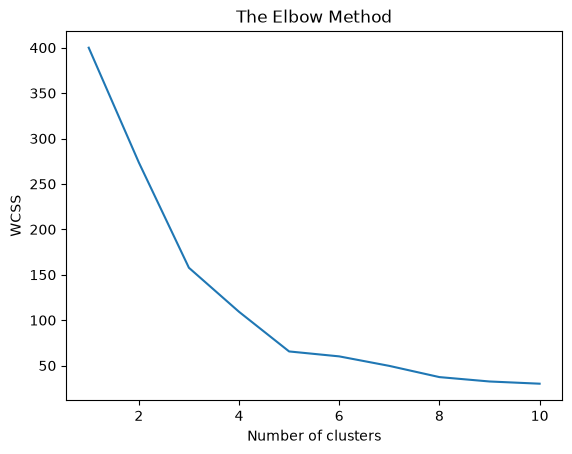

In [5]:
from sklearn.cluster import KMeans
list1=[]
for i in range(1,11):
    kmeans=KMeans(n_clusters=i,init='k-means++',random_state=42)
    kmeans.fit(X_scaled)
    list1.append(kmeans.inertia_)
plt.plot(range(1,11),list1)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

Train a Model:

In [6]:
from sklearn.cluster import KMeans
kmeans=KMeans(n_clusters=5,init='k-means++',random_state=42)
y_kmeans=kmeans.fit_predict(X_scaled)

Display the Cluster lables:

In [7]:
y_kmeans

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

Display the Total WCSS Value:

In [8]:
kmeans.inertia_

65.56840815571681

Display the Final Centroids of Each Cluster:

In [9]:
centroids=kmeans.cluster_centers_
centroids

array([[-0.20091257, -0.02645617],
       [ 0.99158305,  1.23950275],
       [-1.32954532,  1.13217788],
       [ 1.05500302, -1.28443907],
       [-1.30751869, -1.13696536]])

Create a DataFrame to Existing Dataset:

In [10]:
Clustered_data=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [11]:
Clustered_data['Cluster_group']=y_kmeans

Plot the Cluster's Graph:

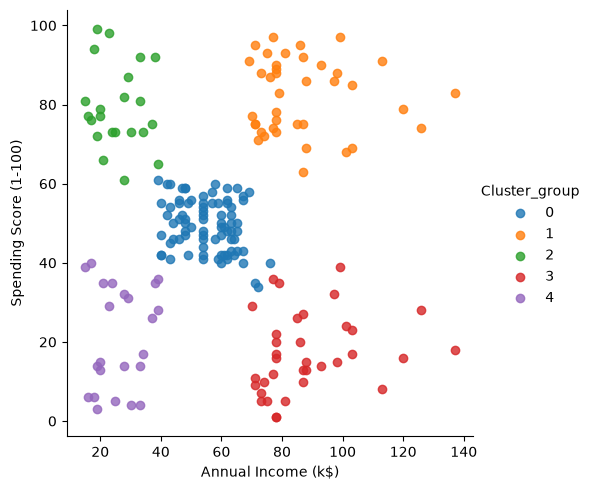

In [12]:
import seaborn as sns
facet=sns.lmplot(data=Clustered_data,x=Clustered_data.columns[3],y=Clustered_data.columns[4],hue=Clustered_data.columns[5],fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [13]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,y_kmeans)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.5546571631111091


Find the Best Evaluation score Based on the Value K:

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(k, score)

2 0.3973270007887498
3 0.46658474419000145
4 0.49434988482196784
5 0.5546571631111091
6 0.5138257534676561
7 0.50200146805547
8 0.4550112502601921
9 0.4566624374485964
10 0.44475993501732874


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [15]:
cluster_profile=Clustered_data.groupby('Cluster_group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

               Annual Income (k$)  Spending Score (1-100)
Cluster_group                                            
0                       55.296296               49.518519
1                       86.538462               82.128205
2                       25.727273               79.363636
3                       88.200000               17.114286
4                       26.304348               20.913043


Count the Dataset Lables Based on Uniques:

In [16]:
print(Clustered_data['Cluster_group'].value_counts())

Cluster_group
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


Save the Scaling,Model & Cluster_Dataset:

In [17]:
import pickle
sc_filename='StandardScaler.sav'
model_filename='finalized_model.sav'
dataset_filename='Deployment_dataset.sav'
pickle.dump(sc,open(sc_filename,'wb'))
pickle.dump(kmeans,open(model_filename,'wb'))
pickle.dump(cluster_profile,open(dataset_filename,'wb'))